# 02 — Reproduce pairing and spatial holdouts

**Question:** which scenes/patches satisfy the configured overlap, time, cloud
and validity rules, and can nearby geography leak between splits?

The same geographic grid defines a positive pair. This does not mean the sensor
images are pixel-identical. A default seven-day window, 90% smaller-scene overlap,
20% cloud cap and 80% common-valid threshold are configured outside the code.
The synthetic fixture has separated regions so all three spatial holdouts exist.

In [1]:
from pathlib import Path
import json, sys, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/crosssense").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from crosssense.config import load_config, save_config
from crosssense.logging_config import configure_logging
from crosssense.data.synthetic import create_synthetic_fixture
from crosssense.data.pairing import prepare_pairs
from crosssense.data.dataset import load_manifest, load_pair_arrays, PairedPatchDataset
from crosssense.models.training import set_seed

config = load_config(ROOT / "configs/default.yaml")
config.training.device = "cpu"
set_seed(config.seed)
log_path = configure_logging(ROOT / "outputs/logs", "INFO", "notebook-02")
WORK = ROOT / "outputs/notebook_demo"
WORK.mkdir(parents=True, exist_ok=True)
save_config(config, WORK / "config.yaml")
scenes_path = WORK / "synthetic/scenes.csv"
if not scenes_path.exists():
    scenes_path = create_synthetic_fixture(WORK / "synthetic", config.data, config.seed)
manifest_path = WORK / "processed/pairs.csv"
if not manifest_path.exists():
    manifest_path = prepare_pairs(scenes_path, WORK / "processed", config.data, config.seed)
frame = load_manifest(manifest_path)
assert set(frame.source) == {"synthetic"}, "This default notebook is explicitly a synthetic demonstration"
display(Markdown("**SYNTHETIC PIPELINE TEST — no real satellite observations.**"))
display(pd.DataFrame([{"python": platform.python_version(), "numpy": version("numpy"), "torch": version("torch"), "rasterio": version("rasterio"), "seed": config.seed, "device": config.training.device}]))
display(config.to_dict())

**SYNTHETIC PIPELINE TEST — no real satellite observations.**

,python,numpy,torch,rasterio,seed,device
0,3.12.16,2.5.5,2.10.0,1.4.4,42,cpu


{'seed': 42,
 'data': {'patch_size': 32,
  'stride': 32,
  'resolution_m': 10.0,
  'target_crs': 'EPSG:32643',
  'sar_bands': [1, 2],
  'optical_bands': [2, 3, 4, 8],
  'sar_units': 'db',
  'sar_clip_db': [-30.0, 5.0],
  'optical_scale': 10000.0,
  'optical_clip': [0.0, 1.0],
  'min_valid_fraction': 0.8,
  'max_cloud_fraction': 0.2,
  'max_time_gap_days': 7.0,
  'min_overlap': 0.9,
  'geographic_exclusion_m': 500.0,
  'block_size_m': 10000.0,
  'split_buffer_m': 500.0,
  'split_fractions': [0.6, 0.2, 0.2],
  'scene_manifest': None,
  'require_cloud_mask': False,
  'allow_author_pairs_without_time': False},
 'model': {'sar_channels': 2,
  'optical_channels': 4,
  'embedding_dim': 32,
  'width': 16,
  'freeze_backbones': False},
 'training': {'batch_size': 8,
  'epochs': 4,
  'lr': 0.001,
  'temperature': 0.1,
  'device': 'cpu',
  'patience': 5,
  'num_workers': 0},
 'logging': {'level': 'INFO', 'output_dir': 'outputs/logs'}}

In [2]:
from crosssense.evaluation.splits import validate_splits
manifest_path = prepare_pairs(scenes_path, WORK / "processed", config.data, config.seed)
frame = load_manifest(manifest_path)
validate_splits(frame, buffer_m=config.data.split_buffer_m)
rejections = pd.read_csv(WORK / "processed/rejections.csv")
display(frame[["pair_id", "block_id", "split", "sar_time", "optical_time", "time_gap_days", "cloud_fraction", "valid_fraction"]].head(12))
display(frame.groupby("split").agg(pairs=("pair_id", "size"), blocks=("block_id", "nunique")))
display(rejections.groupby("reason").size().rename("rejections").to_frame())

,pair_id,block_id,split,sar_time,optical_time,time_gap_days,cloud_fraction,valid_fraction
0,pair-d8c86b729d3b68a2dbd1,geo-641381bb1b12,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
1,pair-d528ec489cb91ee1b333,geo-641381bb1b12,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
2,pair-6408e4bfcbc4202a99a0,geo-641381bb1b12,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
3,pair-c0abb4251b2f5f5be7d7,geo-641381bb1b12,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
4,pair-e4da00fe001c18eff233,geo-1781c2c434db,validation,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
5,pair-bd6e68fb1963bdfcc4a6,geo-1781c2c434db,validation,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
6,pair-eb36b2e6c1b8c7c655b8,geo-1781c2c434db,validation,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
7,pair-772778f4ede207b7a815,geo-1781c2c434db,validation,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
8,pair-3f1e23d7afb16adedc30,geo-257eeacc6aa4,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0
9,pair-a0f1f4a3d59a2281196a,geo-257eeacc6aa4,train,2024-01-10T00:00:00+00:00,2024-01-12T00:00:00+00:00,2.0,0.0,1.0


,pairs,blocks
split,,
test,8,2
train,20,5
validation,8,2


,rejections
reason,
geographic_overlap,72


## Geographic assignment

All acquisitions in a spatial component stay together. Footprint overlap or
proximity can merge blocks before assignment, including neighbors across a block
boundary. Random adjacent-patch splits would expose nearly identical ground in
training and test and can inflate retrieval scores. The validation below checks
blocks and footprints independently of how the assignments were generated.

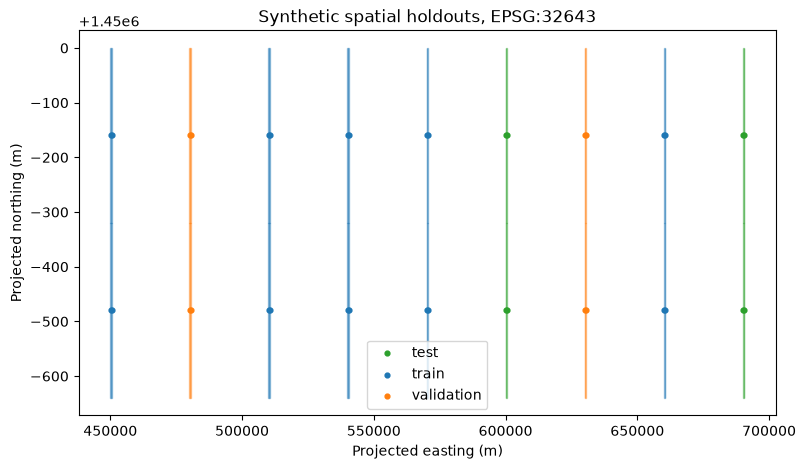

In [3]:
from matplotlib.patches import Rectangle
colors = {"train": "tab:blue", "validation": "tab:orange", "test": "tab:green"}
fig, ax = plt.subplots(figsize=(9, 5))
for row in frame.itertuples():
    ax.add_patch(Rectangle((row.minx, row.miny), row.maxx-row.minx, row.maxy-row.miny, color=colors[row.split], alpha=.4))
for split, rows in frame.groupby("split"):
    ax.scatter(rows.x, rows.y, label=split, color=colors[split], s=12)
ax.autoscale(); ax.set(xlabel="Projected easting (m)", ylabel="Projected northing (m)", title="Synthetic spatial holdouts, EPSG:32643")
ax.legend(); plt.show()

## Deliberate time mismatch and leakage failures

The following experiments intentionally violate a rule. Expected errors are
caught and displayed; an unexpected success raises an assertion. Rejection CSVs
preserve why candidates were dropped. These are actual computed outcomes on
fixtures, not statements that every source product was validated.

In [4]:
import copy
strict = copy.deepcopy(config.data)
strict.max_time_gap_days = 0
strict_path = prepare_pairs(scenes_path, WORK / "strict_time", strict, config.seed)
strict_pairs = pd.read_csv(strict_path)
strict_rejections = pd.read_csv(WORK / "strict_time/rejections.csv")
assert len(strict_pairs) == 0
assert "time_gap" in set(strict_rejections.reason)
display(strict_rejections.groupby("reason").size().to_frame("count"))

leaky = frame.copy()
first_block = leaky.block_id.iloc[0]
members = leaky.index[leaky.block_id == first_block]
assert len(members) >= 2
leaky.loc[members[0], "split"] = "test" if leaky.loc[members[1], "split"] != "test" else "train"
try:
    validate_splits(leaky, config.data.split_buffer_m)
except ValueError as exc:
    display(Markdown(f"**Observed expected leakage rejection:** `{exc}`"))
else:
    raise AssertionError("Deliberately shared spatial block was not rejected")
display(Markdown(f"**Observed:** {len(frame)} default pairs; zero with a zero-day time window. All default split checks passed. Inspect `{WORK / 'processed/rejections.csv'}` for rejected candidates."))

,count
reason,
geographic_overlap,72
time_gap,9


**Observed expected leakage rejection:** `Spatial block leakage: block appears in multiple splits`

**Observed:** 36 default pairs; zero with a zero-day time window. All default split checks passed. Inspect `C:\Users\agent\Downloads\coding\CrossSense\outputs\notebook_demo\processed\rejections.csv` for rejected candidates.